In [7]:
import os
from getpass import getpass
from sqlalchemy import create_engine

password = getpass("PostgreSQL password: ")

engine = create_engine(
    "postgresql+psycopg://jenish@localhost:5432/retail_intelligence",
    connect_args={"password": password}
)

with engine.connect() as conn:
    print("PostgreSQL connection successful!")

PostgreSQL connection successful!


In [10]:
import pandas as pd

file_path = "/Users/jenish/Downloads/data_analyst/retail-sales-analysis/data/processed/supermart_clean.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 9994
Columns: 11


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,2017-08-11,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,2017-08-11,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,2017-12-06,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,2016-11-10,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,2016-11-10,South,2355,0.26,918.45,Tamil Nadu


In [11]:
from sqlalchemy import inspect, text

table_name = "supermart_sales"

inspector = inspect(engine)

if inspector.has_table(table_name):
    print(f"Table '{table_name}' already exists. Import skipped.")
else:
    df.to_sql(
        name=table_name,
        con=engine,
        if_exists="fail",
        index=False,
        chunksize=1000
    )
    print(f"Imported {len(df):,} rows into '{table_name}'.")

with engine.connect() as conn:
    count = conn.execute(
        text("SELECT COUNT(*) FROM supermart_sales")
    ).scalar_one()

print(f"Rows verified in PostgreSQL: {count:,}")

Table 'supermart_sales' already exists. Import skipped.
Rows verified in PostgreSQL: 9,994


In [12]:
from sqlalchemy import text

query = """
SELECT
    category,
    SUM(sales) AS total_sales,
    SUM(profit) AS total_profit
FROM supermart_sales
GROUP BY category
ORDER BY total_sales DESC;
"""

with engine.connect() as conn:
    result = conn.execute(text(query))
    rows = result.fetchall()
    columns = result.keys()

pd.DataFrame(rows, columns=columns)

,category,total_sales,total_profit
0,"Eggs, Meat & Fish",2267401.00,567357.22
1,Snacks,2237546.00,568178.85
2,Food Grains,2115272.00,529162.64
3,Bakery,2112281.00,528521.06
4,Fruits & Veggies,2100727.00,530400.38
5,Beverages,2085313.00,525605.76
6,Oil & Masala,2038442.00,497895.29


In [13]:
from sqlalchemy import text
import pandas as pd

query = """
SELECT
    DATE_TRUNC('month', order_date::date)::date AS sales_month,
    SUM(sales) AS total_sales,
    SUM(profit) AS total_profit,
    COUNT(*) AS order_records
FROM supermart_sales
GROUP BY 1
ORDER BY 1;
"""

with engine.connect() as conn:
    monthly_df = pd.read_sql(text(query), conn)

display(monthly_df)

,sales_month,total_sales,total_profit,order_records
0,2015-01-01,203014.0,54689.18,131
1,2015-02-01,120444.0,32737.87,86
2,2015-03-01,260072.0,66217.50,168
3,2015-04-01,176187.0,46030.20,121
4,2015-05-01,218740.0,50899.84,148
5,2015-06-01,209191.0,51276.99,137
6,2015-07-01,229055.0,56202.42,156
7,2015-08-01,211451.0,48499.68,150
8,2015-09-01,356192.0,89985.80,239
9,2015-10-01,226102.0,59400.29,145


In [16]:
query = """
WITH monthly_sales AS (
    SELECT
        DATE_TRUNC('month', Order_Date::date)::date AS sales_month,
        SUM(sales) AS total_sales
    FROM supermart_sales
    GROUP BY 1
)
SELECT
    sales_month,
    total_sales,
    LAG(total_sales) OVER (ORDER BY sales_month) AS previous_month_sales,
    ROUND(
        100.0 * (
            total_sales - LAG(total_sales) OVER (ORDER BY sales_month)
        ) / NULLIF(
            LAG(total_sales) OVER (ORDER BY sales_month), 0
        ),
        2
    ) AS mom_growth_pct
FROM monthly_sales
ORDER BY sales_month;
"""

with engine.connect() as conn:
    growth_df = pd.read_sql(text(query), conn)

display(growth_df)

,sales_month,total_sales,previous_month_sales,mom_growth_pct
0,2015-01-01,203014.0,NaN,NaN
1,2015-02-01,120444.0,203014.0,-40.67
2,2015-03-01,260072.0,120444.0,115.93
3,2015-04-01,176187.0,260072.0,-32.25
4,2015-05-01,218740.0,176187.0,24.15
5,2015-06-01,209191.0,218740.0,-4.37
6,2015-07-01,229055.0,209191.0,9.50
7,2015-08-01,211451.0,229055.0,-7.69
8,2015-09-01,356192.0,211451.0,68.45
9,2015-10-01,226102.0,356192.0,-36.52


In [20]:
from sqlalchemy import text
import pandas as pd

seasonality_query = """
SELECT
    month_number,
    TO_CHAR(
        TO_DATE(month_number::text, 'MM'),
        'FMMonth'
    ) AS month_name,
    ROUND(AVG(monthly_sales), 2) AS avg_monthly_sales,
    ROUND(MIN(monthly_sales), 2) AS min_monthly_sales,
    ROUND(MAX(monthly_sales), 2) AS max_monthly_sales
FROM (
    SELECT
        EXTRACT(MONTH FROM order_date::date)::int AS month_number,
        DATE_TRUNC('month', order_date::date)::date AS sales_month,
        SUM(sales) AS monthly_sales
    FROM supermart_sales
    GROUP BY 1, 2
) AS monthly
GROUP BY month_number
ORDER BY avg_monthly_sales DESC;
"""

with engine.connect() as conn:
    seasonality_df = pd.read_sql(
        text(seasonality_query), conn
    )

display(seasonality_df)

,month_number,month_name,avg_monthly_sales,min_monthly_sales,max_monthly_sales
0,11,November,448707.75,396619.0,553847.0
1,9,September,426535.25,355404.0,589384.0
2,12,December,400677.50,367865.0,468719.0
3,5,May,312831.75,218740.0,388739.0
4,3,March,311799.00,242347.0,456482.0
5,10,October,309347.25,226102.0,413301.0
6,8,August,305107.50,211451.0,393698.0
7,7,July,276870.75,194498.0,366018.0
8,6,June,257173.50,209191.0,334982.0
9,4,April,257088.00,176187.0,339747.0


In [21]:
# Highest and lowest average-sales months
best_month = seasonality_df.loc[
    seasonality_df["avg_monthly_sales"].idxmax()
]

worst_month = seasonality_df.loc[
    seasonality_df["avg_monthly_sales"].idxmin()
]

print("HIGHEST AVERAGE SALES")
print(f"Month: {best_month['month_name'].strip()}")
print(f"Average sales: {best_month['avg_monthly_sales']:,.2f}")

print("\nLOWEST AVERAGE SALES")
print(f"Month: {worst_month['month_name'].strip()}")
print(f"Average sales: {worst_month['avg_monthly_sales']:,.2f}")

difference = (
    best_month["avg_monthly_sales"]
    - worst_month["avg_monthly_sales"]
)

print(f"\nAverage sales difference: {difference:,.2f}")

HIGHEST AVERAGE SALES
Month: November
Average sales: 448,707.75

LOWEST AVERAGE SALES
Month: February
Average sales: 207,575.25

Average sales difference: 241,132.50


In [22]:
from sqlalchemy import text
import pandas as pd

profitability_query = """
SELECT
    category,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct,
    ROUND(AVG(profit), 2) AS avg_profit_per_record
FROM supermart_sales
GROUP BY category
ORDER BY profit_margin_pct ASC;
"""

with engine.connect() as conn:
    profitability_df = pd.read_sql(
        text(profitability_query), conn
    )

display(profitability_df)

,category,order_records,total_sales,total_profit,profit_margin_pct,avg_profit_per_record
0,Oil & Masala,1361,2038442.0,497895.29,24.43,365.83
1,Food Grains,1398,2115272.0,529162.64,25.02,378.51
2,Bakery,1413,2112281.0,528521.06,25.02,374.04
3,"Eggs, Meat & Fish",1490,2267401.0,567357.22,25.02,380.78
4,Beverages,1400,2085313.0,525605.76,25.21,375.43
5,Fruits & Veggies,1418,2100727.0,530400.38,25.25,374.05
6,Snacks,1514,2237546.0,568178.85,25.39,375.28


In [23]:
from sqlalchemy import text
import pandas as pd

discount_query = """
SELECT
    CASE
        WHEN discount = 0 THEN '0% discount'
        WHEN discount <= 0.10 THEN '1-10% discount'
        WHEN discount <= 0.20 THEN '11-20% discount'
        ELSE 'Above 20% discount'
    END AS discount_band,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM supermart_sales
GROUP BY 1
ORDER BY MIN(discount);
"""

with engine.connect() as conn:
    discount_df = pd.read_sql(text(discount_query), conn)

display(discount_df)

,discount_band,order_records,total_sales,total_profit,profit_margin_pct
0,1-10% discount,366,532943.0,132451.16,24.85
1,11-20% discount,3716,5585140.0,1394038.92,24.96
2,Above 20% discount,5912,8838899.0,2220631.12,25.12


In [25]:
from sqlalchemy import text
import pandas as pd

category_discount_query = """
SELECT
    category,
    CASE
        WHEN discount = 0 THEN '0% discount'
        WHEN discount <= 0.10 THEN '1-10% discount'
        WHEN discount <= 0.20 THEN '11-20% discount'
        ELSE 'Above 20% discount'
    END AS discount_band,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM supermart_sales
GROUP BY category, discount_band
ORDER BY category, profit_margin_pct ASC;
"""

with engine.connect() as conn:
    category_discount_df = pd.read_sql(
        text(category_discount_query), conn
    )

display(category_discount_df)

,category,discount_band,order_records,total_sales,total_profit,profit_margin_pct
0,Bakery,1-10% discount,48,63837.0,14611.75,22.89
1,Bakery,11-20% discount,525,799718.0,195928.97,24.50
2,Bakery,Above 20% discount,840,1248726.0,317980.34,25.46
3,Beverages,11-20% discount,501,748314.0,183733.28,24.55
4,Beverages,1-10% discount,51,80553.0,20346.80,25.26
5,Beverages,Above 20% discount,848,1256446.0,321525.68,25.59
6,"Eggs, Meat & Fish",11-20% discount,548,843721.0,208273.93,24.69
7,"Eggs, Meat & Fish",Above 20% discount,890,1347913.0,339412.29,25.18
8,"Eggs, Meat & Fish",1-10% discount,52,75767.0,19671.00,25.96
9,Food Grains,11-20% discount,523,792269.0,194791.60,24.59


In [26]:
from sqlalchemy import text
import pandas as pd

loss_query = """
SELECT
    category,
    "sub_category" AS sub_category,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM supermart_sales
GROUP BY category, "sub_category"
HAVING SUM(profit) < 0
ORDER BY SUM(profit) ASC;
"""

with engine.connect() as conn:
    loss_df = pd.read_sql(text(loss_query), conn)

display(loss_df)

,category,sub_category,order_records,total_sales,total_profit,profit_margin_pct


In [27]:
from sqlalchemy import text
import pandas as pd

subcategory_query = """
SELECT
    category,
    sub_category,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM supermart_sales
GROUP BY category, sub_category
ORDER BY profit_margin_pct ASC
LIMIT 10;
"""

with engine.connect() as conn:
    subcategory_df = pd.read_sql(
        text(subcategory_query), conn
    )

display(subcategory_df)

,category,sub_category,order_records,total_sales,total_profit,profit_margin_pct
0,Oil & Masala,Spices,447,672876.0,160302.60,23.82
1,"Eggs, Meat & Fish",Chicken,348,520497.0,124049.89,23.83
2,Food Grains,Atta & Flour,353,534649.0,127861.10,23.91
3,Oil & Masala,Masalas,463,697480.0,168999.11,24.23
4,Fruits & Veggies,Fresh Fruits,369,551212.0,134668.35,24.43
5,Bakery,Cakes,452,685612.0,168398.46,24.56
6,Bakery,Biscuits,459,684083.0,169357.62,24.76
7,"Eggs, Meat & Fish",Mutton,394,611200.0,151389.40,24.77
8,Snacks,Cookies,520,768213.0,190643.70,24.82
9,Food Grains,Dals & Pulses,343,523371.0,130232.29,24.88


In [28]:
from sqlalchemy import text
import pandas as pd

region_query = """
SELECT
    region,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct,
    RANK() OVER (ORDER BY SUM(profit) DESC) AS profit_rank
FROM supermart_sales
GROUP BY region
ORDER BY profit_rank;
"""

with engine.connect() as conn:
    region_df = pd.read_sql(text(region_query), conn)

display(region_df)

,region,order_records,total_sales,total_profit,profit_margin_pct,profit_rank
0,West,3203,4798743.0,1192004.61,24.84,1
1,East,2848,4248368.0,1074345.58,25.29,2
2,Central,2323,3468156.0,856806.84,24.70,3
3,South,1619,2440461.0,623562.89,25.55,4
4,North,1,1254.0,401.28,32.00,5


In [29]:
from sqlalchemy import text
import pandas as pd

city_query = """
SELECT
    city,
    region,
    COUNT(*) AS order_records,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct,
    RANK() OVER (ORDER BY SUM(profit) DESC) AS profit_rank
FROM supermart_sales
GROUP BY city, region
ORDER BY profit_rank
LIMIT 10;
"""

with engine.connect() as conn:
    city_df = pd.read_sql(text(city_query), conn)

display(city_df)

,city,region,order_records,total_sales,total_profit,profit_margin_pct,profit_rank
0,Bodi,West,164,247873.0,65524.36,26.43,1
1,Perambalur,West,145,215899.0,56035.20,25.95,2
2,Vellore,West,144,225617.0,55517.40,24.61,3
3,Dharmapuri,West,139,220077.0,55299.10,25.13,4
4,Tenkasi,West,153,225701.0,55160.21,24.44,5
5,Madurai,West,135,199144.0,54596.78,27.42,6
6,Tirunelveli,West,150,219492.0,54063.63,24.63,7
7,Kanyakumari,East,142,209930.0,52988.09,25.24,8
8,Karur,West,137,206125.0,52420.11,25.43,9
9,Cumbum,East,136,207283.0,52178.30,25.17,10


In [30]:
from sqlalchemy import text
import pandas as pd

kpi_query = """
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT "order_id") AS unique_orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct,
    ROUND(AVG(discount)::numeric, 4) AS avg_discount
FROM supermart_sales;
"""

with engine.connect() as conn:
    kpi_df = pd.read_sql(text(kpi_query), conn)

display(kpi_df)

,total_records,unique_orders,total_sales,total_profit,profit_margin_pct,avg_discount
0,9994,9994,14956982.0,3747121.2,25.05,0.2268


Matplotlib is building the font cache; this may take a moment.


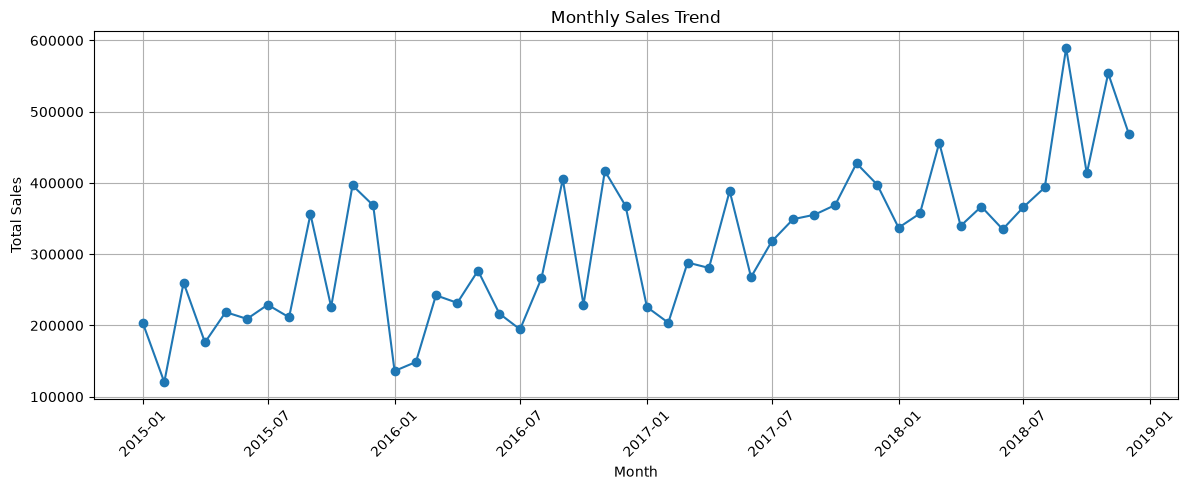

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

growth_df["sales_month"] = pd.to_datetime(
    growth_df["sales_month"]
)

plt.figure(figsize=(12, 5))
plt.plot(
    growth_df["sales_month"],
    growth_df["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Category-wise sales and profit from PostgreSQL
category_df = pd.read_sql("""
    SELECT
        category,
        SUM(sales) AS total_sales,
        SUM(profit) AS total_profit,
        ROUND(
            (SUM(profit) / NULLIF(SUM(sales), 0) * 100)::numeric,
            2
        ) AS profit_margin_pct
    FROM supermart_sales
    GROUP BY category
    ORDER BY total_sales DESC;
""", engine)

display(category_df)

,category,total_sales,total_profit,profit_margin_pct
0,"Eggs, Meat & Fish",2267401.0,567357.22,25.02
1,Snacks,2237546.0,568178.85,25.39
2,Food Grains,2115272.0,529162.64,25.02
3,Bakery,2112281.0,528521.06,25.02
4,Fruits & Veggies,2100727.0,530400.38,25.25
5,Beverages,2085313.0,525605.76,25.21
6,Oil & Masala,2038442.0,497895.29,24.43


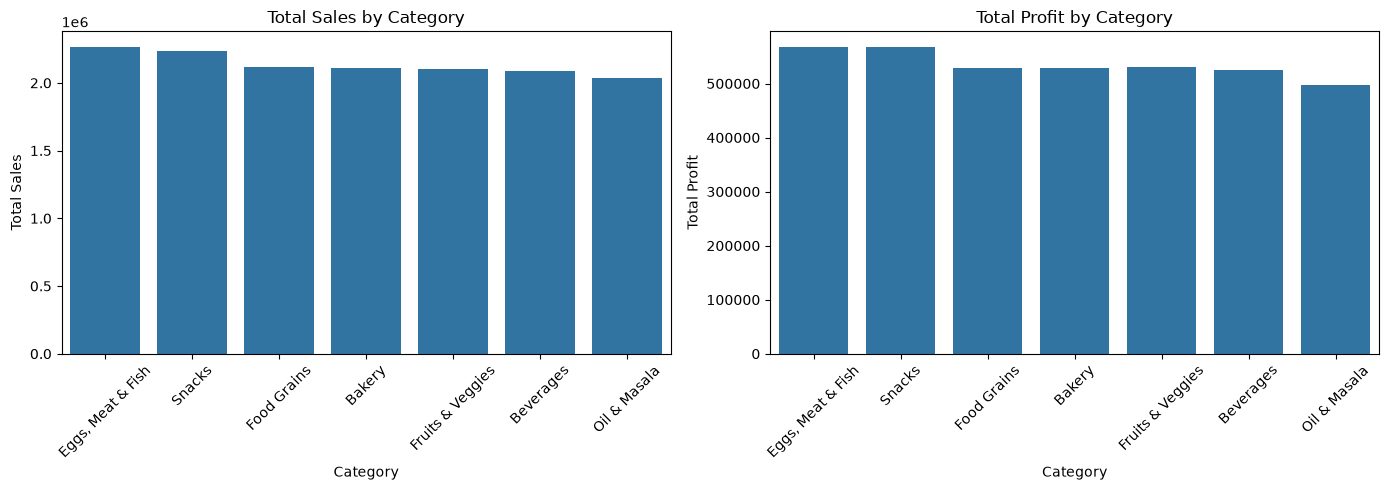

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales by category
sns.barplot(
    data=category_df,
    x="category",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=45)

# Profit by category
sns.barplot(
    data=category_df,
    x="category",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Total Profit")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse existing region_df if it is available
display(region_df)

,region,order_records,total_sales,total_profit,profit_margin_pct,profit_rank
0,West,3203,4798743.0,1192004.61,24.84,1
1,East,2848,4248368.0,1074345.58,25.29,2
2,Central,2323,3468156.0,856806.84,24.70,3
3,South,1619,2440461.0,623562.89,25.55,4
4,North,1,1254.0,401.28,32.00,5


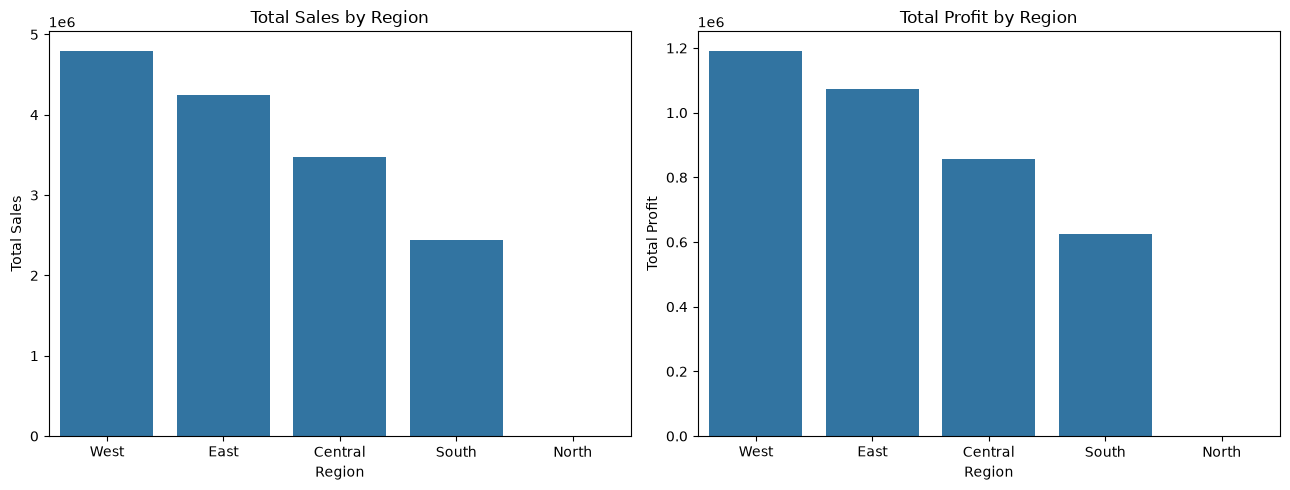

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=region_df,
    x="region",
    y="total_sales",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Total Sales")

sns.barplot(
    data=region_df,
    x="region",
    y="total_profit",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [38]:
city_df = pd.read_sql("""
    SELECT
        city,
        region,
        COUNT(*) AS total_records,
        SUM(sales) AS total_sales,
        SUM(profit) AS total_profit,
        ROUND(
            (SUM(profit) / NULLIF(SUM(sales), 0) * 100)::numeric,
            2
        ) AS profit_margin_pct
    FROM supermart_sales
    GROUP BY city, region
    ORDER BY total_profit DESC
    LIMIT 10;
""", engine)

display(city_df)

,city,region,total_records,total_sales,total_profit,profit_margin_pct
0,Bodi,West,164,247873.0,65524.36,26.43
1,Perambalur,West,145,215899.0,56035.20,25.95
2,Vellore,West,144,225617.0,55517.40,24.61
3,Dharmapuri,West,139,220077.0,55299.10,25.13
4,Tenkasi,West,153,225701.0,55160.21,24.44
5,Madurai,West,135,199144.0,54596.78,27.42
6,Tirunelveli,West,150,219492.0,54063.63,24.63
7,Kanyakumari,East,142,209930.0,52988.09,25.24
8,Karur,West,137,206125.0,52420.11,25.43
9,Cumbum,East,136,207283.0,52178.30,25.17


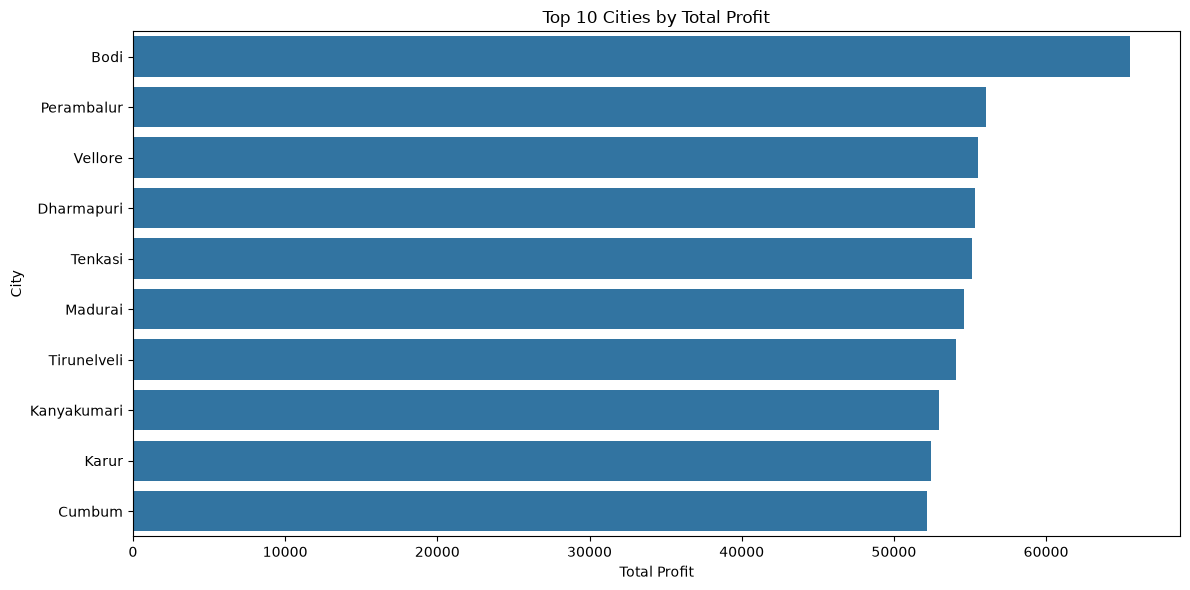

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=city_df,
    x="total_profit",
    y="city"
)

plt.title("Top 10 Cities by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("City")
plt.tight_layout()
plt.show()